# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Dewi Rahma Fauziah
- **Email:** fauziahrahma138@gmail.com
- **ID Dicoding:** DS014B6X0441

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada tahun 2011–2012, pada jam berapa rata-rata jumlah penyewaan sepeda mencapai nilai tertinggi, dan bagaimana pola rata-rata penyewaan berubah sepanjang hari?

- **Pertanyaan 2:** Pada tahun 2011–2012, musim apa yang memiliki rata-rata jumlah penyewaan sepeda harian tertinggi, dan bagaimana perbedaan rata-rata penyewaan harian antar musim?


## Import Semua Packages/Library yang Digunakan

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df Bike Sharing

In [37]:
# Memuat dataset
hour_df = pd.read_csv('hour.csv')
day_df = pd.read_csv('day.csv')

# Melihat ukuran dataset
print("Ukuran dataset per jam:", hour_df.shape)
print("Ukuran dataset per hari:", day_df.shape)

# Menampilkan 5 baris pertama
display(hour_df.head())
display(day_df.head())

Ukuran dataset per jam: (17379, 17)
Ukuran dataset per hari: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset `hour.csv` terdiri dari 17.379 baris dan 17 kolom yang berisi data penyewaan sepeda berdasarkan jam.
- Dataset `day.csv` terdiri dari 731 baris dan 16 kolom yang berisi data penyewaan sepeda berdasarkan hari.
- Kedua dataset mencakup periode tahun 2011–2012 dan digunakan untuk menganalisis pola penyewaan sepeda berdasarkan waktu.

### Assessing Data

#### Identifying data problem

In [38]:

# Memeriksa informasi dataset
print("=== Informasi Dataset hour_df ===")
hour_df.info()

print("\n=== Informasi Dataset day_df ===")
day_df.info()

# Memeriksa missing values
print("\n=== Missing Values hour_df ===")
print(hour_df.isna().sum())

print("\n=== Missing Values day_df ===")
print(day_df.isna().sum())

# Memeriksa data duplikat
print("\n=== Data Duplikat ===")
print("Jumlah data duplikat hour_df:", hour_df.duplicated().sum())
print("Jumlah data duplikat day_df:", day_df.duplicated().sum())

# Memeriksa statistik deskriptif
print("\n=== Statistik Deskriptif hour_df ===")
display(hour_df.describe())

print("\n=== Statistik Deskriptif day_df ===")
display(day_df.describe())

# Memeriksa nilai unik pada kolom kategorikal
print("\n=== Nilai Unik Kolom Kategorikal hour_df ===")
categorical_columns = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit'
]

for column in categorical_columns:
    print(f"{column}: {sorted(hour_df[column].unique())}")

# Memeriksa konsistensi jumlah penyewaan
inconsistent_count = hour_df[
    hour_df['cnt'] != hour_df['casual'] + hour_df['registered']
]

print(
    "\nJumlah baris dengan total penyewaan tidak konsisten:",
    len(inconsistent_count)
)

# Memeriksa kemungkinan outlier pada jumlah penyewaan
Q1 = hour_df['cnt'].quantile(0.25)
Q3 = hour_df['cnt'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = hour_df[
    (hour_df['cnt'] < lower_bound) |
    (hour_df['cnt'] > upper_bound)
]

print("\nBatas bawah:", lower_bound)
print("Batas atas:", upper_bound)
print("Jumlah kandidat outlier:", len(outliers))

# Melihat 10 kandidat outlier dengan jumlah penyewaan tertinggi
display(
    outliers[['dteday', 'hr', 'casual', 'registered', 'cnt']]
    .sort_values(by='cnt', ascending=False)
    .head(10)
)

=== Informasi Dataset hour_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

=== Informasi 

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



=== Statistik Deskriptif day_df ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



=== Nilai Unik Kolom Kategorikal hour_df ===
season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
hr: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Jumlah baris dengan total penyewaan tidak konsisten: 0

Batas bawah: -321.5
Batas atas: 642.5
Jumlah kandidat outlier: 505


,dteday,hr,casual,registered,cnt
14773,2012-09-12,18,91,886,977
14964,2012-09-20,17,91,885,976
14748,2012-09-11,17,168,802,970
14725,2012-09-10,18,111,857,968
15084,2012-09-25,17,107,860,967
15780,2012-10-24,17,87,876,963
10622,2012-03-23,17,264,693,957
15108,2012-09-26,17,77,876,953
15444,2012-10-10,17,91,857,948
15588,2012-10-16,17,104,839,943


**Steps to Take:**

- Memeriksa informasi dataset untuk mengetahui jumlah baris, kolom, dan tipe data setiap kolom.
- Memeriksa missing values dan data duplikat untuk memastikan kelengkapan serta keunikan data.
- Memeriksa statistik deskriptif untuk memahami distribusi data.
- Memeriksa konsistensi jumlah penyewaan dengan membandingkan kolom `cnt` terhadap penjumlahan `casual` dan `registered`.
- Mengidentifikasi kandidat outlier pada kolom `cnt` menggunakan metode Interquartile Range (IQR), kemudian meninjau nilainya sebelum menentukan penanganan yang sesuai.
- Memeriksa nilai unik kolom kategorikal seperti `season` dan `weathersit` agar kode kategorinya lebih mudah dipahami saat analisis.

**Insight:** (Opsional)
- Dataset `hour_df` memiliki 17.379 baris dan 17 kolom, sedangkan `day_df` memiliki 731 baris dan 16 kolom.
- Hasil pemeriksaan menunjukkan bahwa kedua dataset tidak memiliki missing values maupun baris duplikat.
- Kolom `dteday` masih bertipe `object`, sehingga perlu dikonversi menjadi `datetime` pada tahap Cleaning Data.
- Pemeriksaan konsistensi menunjukkan tidak ada nilai `cnt` yang berbeda dari hasil penjumlahan `casual` dan `registered`.
- Metode Interquartile Range (IQR) mendeteksi 505 kandidat outlier pada kolom `cnt`, dengan batas atas 642,5. Beberapa nilai penyewaan tertinggi tercatat pada pukul 17.00–18.00. Nilai tersebut tidak otomatis menunjukkan kesalahan data sehingga tidak langsung dihapus.
- Kolom `season` dan `weathersit` menggunakan angka sebagai kode kategori. Makna setiap kode perlu mengacu pada keterangan dataset agar hasil analisis dapat diinterpretasikan dengan tepat.

### Cleaning Data

#### Fixing data problem

In [39]:
# Mengubah tipe data kolom dteday menjadi datetime
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# Memeriksa tipe data setelah perubahan
print("Tipe data dteday pada hour_df:", hour_df['dteday'].dtype)
print("Tipe data dteday pada day_df:", day_df['dteday'].dtype)

# Menyimpan kedua dataset hasil cleaning
from pathlib import Path

Path("data").mkdir(exist_ok=True)

hour_df.to_csv("data/hour_clean.csv", index=False)
day_df.to_csv("data/day_clean.csv", index=False)

print("hour_clean.csv dan day_clean.csv berhasil disimpan!")


Tipe data dteday pada hour_df: datetime64[ns]
Tipe data dteday pada day_df: datetime64[ns]
hour_clean.csv dan day_clean.csv berhasil disimpan!


**Insight:** (Opsional)
- Kolom `dteday` pada dataset `hour_df` dan `day_df` telah dikonversi menjadi tipe data `datetime64[ns]` agar dapat digunakan untuk analisis berdasarkan tanggal.
- Tidak ada baris yang dihapus karena hasil pemeriksaan tidak menunjukkan adanya missing values maupun data duplikat.
- Kandidat outlier pada kolom `cnt` tetap dipertahankan karena nilai yang tinggi belum tentu merupakan kesalahan data dan dapat mencerminkan tingginya permintaan penyewaan sepeda pada jam tertentu.
- Kolom `season` dan `weathersit` tetap menggunakan kode angka sesuai dataset. Label kategori akan ditambahkan pada visualisasi agar hasil analisis lebih mudah dipahami.
- Dataset hasil cleaning disimpan sebagai `hour_clean.csv` dan `day_clean.csv` untuk digunakan pada tahap analisis dan pembuatan dashboard.

## Exploratory Data Analysis (EDA)

### Explore Bike Sharing Data

In [40]:
# EDA 1: Rata-rata penyewaan sepeda berdasarkan jam
rentals_by_hour = (
    hour_df.groupby('hr')['cnt']
    .mean()
    .reset_index()
    .rename(columns={'cnt': 'avg_rentals'})
)

display(rentals_by_hour)

# EDA 2: Rata-rata penyewaan sepeda harian berdasarkan musim
rentals_by_season = (
    day_df.groupby('season')['cnt']
    .mean()
    .reset_index()
    .rename(columns={'cnt': 'avg_rentals'})
)

display(rentals_by_season)

,hr,avg_rentals
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


,season,avg_rentals
0,1,2604.132597
1,2,4992.331522
2,3,5644.303191
3,4,4728.162921


**Insight:** (Opsional)
- Rata-rata penyewaan sepeda berubah sepanjang hari. Rata-rata penyewaan tertinggi terjadi pada pukul **17.00**, yaitu sekitar **461,45 penyewaan per jam**, diikuti pukul **18.00** sebesar **425,51 penyewaan per jam**. Sementara itu, rata-rata terendah terjadi pada pukul **04.00**, yaitu sekitar **6,35 penyewaan per jam**. Pola ini menunjukkan bahwa sore hari merupakan waktu dengan permintaan penyewaan tertinggi, sehingga ketersediaan sepeda perlu menjadi prioritas pada jam tersebut.

- Rata-rata penyewaan sepeda harian berbeda antar musim. **Musim 3** memiliki rata-rata penyewaan tertinggi, yaitu sekitar **5.644,30 penyewaan per hari**, diikuti musim 2 sebesar **4.992,33**, musim 4 sebesar **4.728,16**, dan musim 1 sebesar **2.604,13 penyewaan per hari**. Hasil ini menunjukkan bahwa pengelola dapat menyesuaikan ketersediaan sepeda berdasarkan musim, dengan perhatian lebih pada musim yang memiliki rata-rata permintaan lebih tinggi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pada tahun 2011–2012, pada jam berapa rata-rata jumlah penyewaan sepeda mencapai nilai tertinggi, dan bagaimana pola rata-rata penyewaan berubah sepanjang hari?

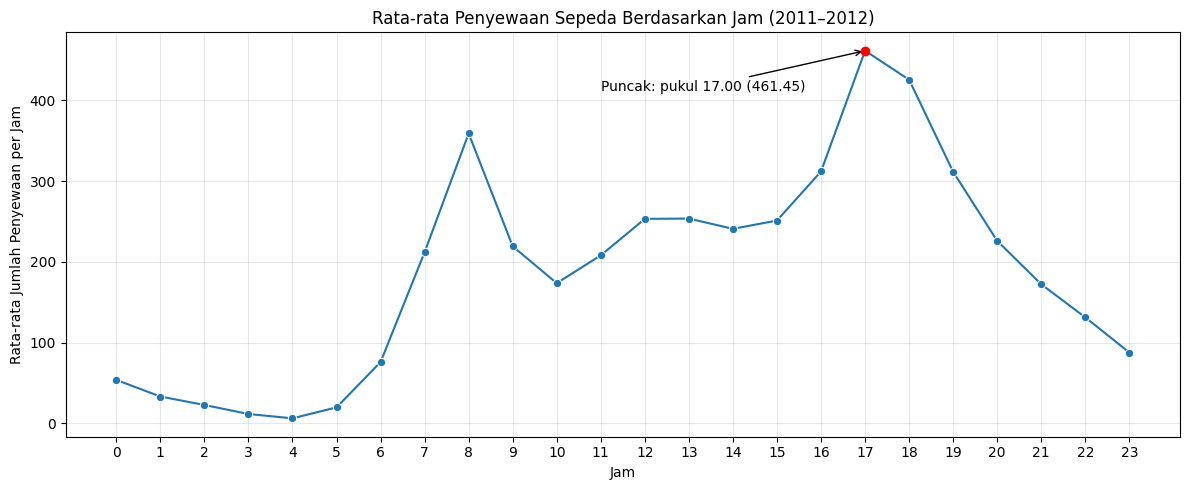

In [41]:
# Menghitung rata-rata penyewaan sepeda berdasarkan jam
rentals_by_hour = hour_df.groupby('hr')['cnt'].mean()

# Menentukan jam dengan rata-rata penyewaan tertinggi
peak_hour = rentals_by_hour.idxmax()
peak_rentals = rentals_by_hour.max()

# Membuat grafik garis
plt.figure(figsize=(12, 5))
sns.lineplot(
    x=rentals_by_hour.index,
    y=rentals_by_hour.values,
    marker='o'
)

# Menandai titik permintaan tertinggi
plt.scatter(peak_hour, peak_rentals, color='red', zorder=5)
plt.annotate(
    f'Puncak: pukul {peak_hour:02d}.00 ({peak_rentals:.2f})',
    xy=(peak_hour, peak_rentals),
    xytext=(peak_hour - 6, peak_rentals - 50),
    arrowprops=dict(arrowstyle='->')
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Jam (2011–2012)')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan per Jam')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Pada tahun 2011–2012, musim apa yang memiliki rata-rata jumlah penyewaan sepeda harian tertinggi, dan bagaimana perbedaan rata-rata penyewaan harian antar musim?

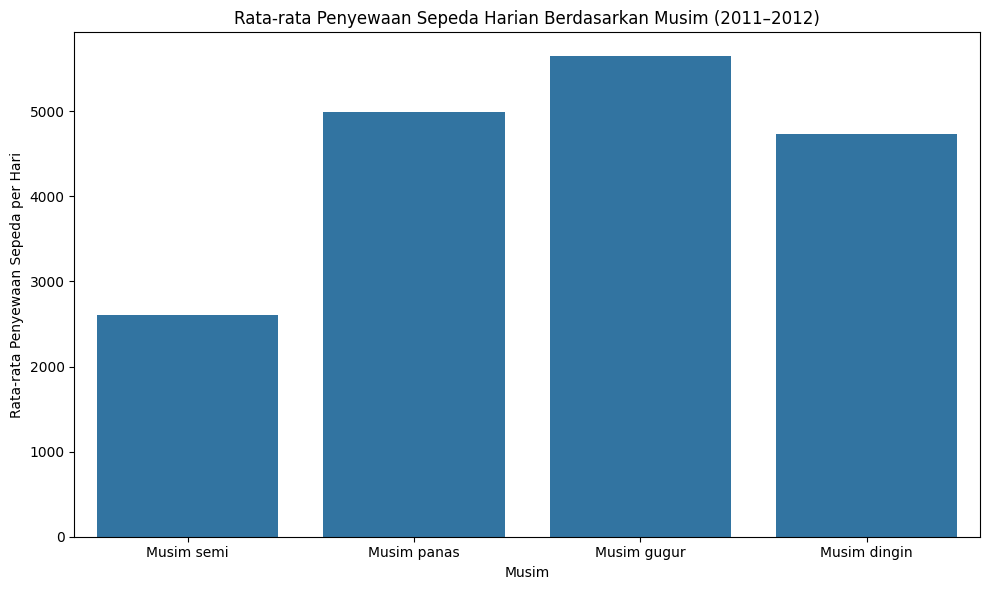

In [42]:
# Pertanyaan 2: Rata-rata penyewaan sepeda harian antar musim

season_labels = {
    1: 'Musim semi',
    2: 'Musim panas',
    3: 'Musim gugur',
    4: 'Musim dingin'
}

# Menghitung rata-rata penyewaan harian berdasarkan musim
rentals_by_season = (
    day_df.groupby('season')['cnt']
    .mean()
    .reset_index()
)

rentals_by_season['season_label'] = (
    rentals_by_season['season'].map(season_labels)
)

# Membuat grafik batang
plt.figure(figsize=(10, 6))
sns.barplot(
    data=rentals_by_season,
    x='season_label',
    y='cnt'
)

plt.title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Musim (2011–2012)')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Penyewaan Sepeda per Hari')
plt.tight_layout()
plt.show()


**Insight:** (Opsional)
- Berdasarkan grafik pertama, rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00, yaitu sekitar 461,45 penyewaan per jam, diikuti pukul 18.00 sebesar 425,51 penyewaan per jam. Sementara itu, rata-rata terendah terjadi pada pukul 04.00, yaitu sekitar 6,35 penyewaan per jam. Hal ini menunjukkan bahwa permintaan penyewaan cenderung meningkat pada pagi hari dan mencapai puncak pada sore hari, sehingga pengelola perlu memprioritaskan ketersediaan sepeda pada jam sibuk.

- Berdasarkan grafik kedua, rata-rata penyewaan sepeda harian tertinggi terjadi pada musim gugur (musim 3), yaitu sekitar 5.644,30 penyewaan per hari. Musim panas (musim 2) memiliki rata-rata 4.992,33 penyewaan per hari, diikuti musim dingin (musim 4) sebesar 4.728,16 penyewaan per hari. Sementara itu, musim semi (musim 1) memiliki rata-rata terendah, yaitu 2.604,13 penyewaan per hari. Hasil ini menunjukkan bahwa pengelola dapat menyesuaikan ketersediaan sepeda berdasarkan pola permintaan pada setiap musim, terutama meningkatkan kesiapan armada pada musim gugur.

## Analisis Lanjutan (Opsional)

In [44]:
# Menghitung rata-rata penyewaan dan jumlah observasi per jam
rentals_by_hour = (
    hour_df.groupby('hr')
    .agg(
        rata_rata_penyewaan=('cnt', 'mean'),
        jumlah_observasi=('cnt', 'size')
    )
    .reset_index()
)

# Mengelompokkan tingkat permintaan berdasarkan rata-rata penyewaan
def categorize_demand(value):
    if value < 100:
        return 'Rendah'
    elif value < 250:
        return 'Sedang'
    else:
        return 'Tinggi'

rentals_by_hour['kategori_permintaan'] = (
    rentals_by_hour['rata_rata_penyewaan']
    .apply(categorize_demand)
)

# Menampilkan rata-rata, jumlah observasi, dan kategori per jam
display(rentals_by_hour)

# Menghitung jumlah jam dan total observasi per kategori
demand_category_count = (
    rentals_by_hour.groupby('kategori_permintaan')
    .agg(
        jumlah_jam=('hr', 'count'),
        total_observasi=('jumlah_observasi', 'sum')
    )
    .reindex(['Rendah', 'Sedang', 'Tinggi'], fill_value=0)
    .reset_index()
)

display(demand_category_count)


,hr,rata_rata_penyewaan,jumlah_observasi,kategori_permintaan
0,0,53.898072,726,Rendah
1,1,33.375691,724,Rendah
2,2,22.869930,715,Rendah
3,3,11.727403,697,Rendah
4,4,6.352941,697,Rendah
5,5,19.889819,717,Rendah
6,6,76.044138,725,Rendah
7,7,212.064649,727,Sedang
8,8,359.011004,727,Tinggi
9,9,219.309491,727,Sedang


,kategori_permintaan,jumlah_jam,total_observasi
0,Rendah,8,5729
1,Sedang,8,5821
2,Tinggi,8,5829


**Insight:** (Opsional)
- Hasil pengelompokan menunjukkan bahwa permintaan penyewaan kategori tinggi terjadi pada pukul 08.00, 12.00–13.00, dan 15.00–19.00. Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, yaitu sebesar 461,45 penyewaan per jam.

- Permintaan kategori rendah terjadi pada pukul 00.00–06.00 dan 23.00. Hasil pengelompokan ini dapat menjadi bahan pertimbangan bagi pengelola dalam menentukan waktu prioritas ketersediaan sepeda berdasarkan tingkat permintaan.

- Pengelompokan tingkat permintaan didasarkan pada rata-rata penyewaan per jam, yaitu kategori rendah untuk rata-rata di bawah 100, sedang untuk rata-rata 100 hingga kurang dari 250, dan tinggi untuk rata-rata 250 atau lebih. Batas tersebut merupakan kriteria yang ditetapkan untuk analisis ini.

## Conclusion & Recommendation

- **Conclusion Pertanyaan 1: Pola Penyewaan Sepeda Berdasarkan Jam**

  Berdasarkan data tahun 2011–2012, rata-rata penyewaan sepeda tertinggi terjadi pada pukul 17.00, yaitu sekitar 461,45 penyewaan per jam, diikuti pukul 18.00 sebesar 425,51 penyewaan per jam. Rata-rata terendah terjadi pada pukul 04.00, yaitu sekitar 6,35 penyewaan per jam. Pola ini menunjukkan bahwa permintaan berubah sepanjang hari dan cenderung mencapai puncak pada sore hari.

- **Conclusion Pertanyaan 2: Pola Penyewaan Sepeda Berdasarkan Musim**

  Berdasarkan data tahun 2011–2012, musim gugur (season 3) memiliki rata-rata penyewaan sepeda harian tertinggi, yaitu sekitar 5.644,30 penyewaan per hari. Berikutnya adalah musim panas (season 2) sebesar 4.992,33, musim dingin (season 4) sebesar 4.728,16, dan musim semi (season 1) sebesar 2.604,13 penyewaan per hari. Artinya, rata-rata penyewaan harian berbeda antar musim dan paling tinggi pada musim gugur.


**Rekomendasi Action Item:**
 - Mengantisipasi jam sibuk: Memprioritaskan ketersediaan sepeda pada pukul 17.00–18.00, serta memperhatikan jam dengan permintaan tinggi lainnya, seperti pukul 08.00, 12.00–13.00, dan 15.00–16.00.

- Menyesuaikan ketersediaan sepeda berdasarkan musim: Merencanakan kesiapan armada lebih tinggi pada musim gugur, karena rata-rata penyewaan harian pada musim ini paling tinggi. Evaluasi kembali kebutuhan armada pada setiap musim menggunakan data permintaan.